# Performance Engineering & Benchmark Analysis Report
## NYC TLC Yellow Taxi Analytics (ComPar 26/27)

This notebook automatically loads JSON metric files exported by `SparkProfiler` from `output/metrics/<op>/profiling_*.json` (with backward compatibility for `output/*Metrics/` and `output/benchmarks/`) and generates:
1. **Full Formatted Tables** (Wall Time, Speedup vs v0 and vs previous version, CPU, GC, I/O wait, Peak Memory, Shuffle R/W, Spill, and Task Skew), including direct export to **Markdown** and **LaTeX**.
2. **Performance Engineering Charts** (Wall Time & Speedup progression, CPU vs GC vs I/O time breakdown, Memory & Shuffle volume, and Spark Stages & Tasks count).
3. **Detailed Stage Breakdown and Task Skew Diagnosis**.


### 1. Automatic Loading of Benchmark JSONs


In [1]:
import os
import re
import glob
import json
import subprocess
import sys

# Ensure matplotlib, seaborn, and tabulate are installed in notebook environment
for pkg in ["matplotlib", "seaborn", "tabulate"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
sns.set_theme(style="whitegrid", palette="deep")

# Detect output directory whether inside Jupyter container (/output) or locally (../output / output)
BASE_OUTPUT = "/output" if os.path.exists("/output") else ("../output" if os.path.exists("../output") else "output")
PLOTS_DIR = os.path.join(BASE_OUTPUT, "plots")
os.makedirs(PLOTS_DIR, exist_ok=True)

def fmt_bytes(b):
    n = float(b)
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if abs(n) < 1024.0:
            return f"{n:.1f} {unit}"
        n /= 1024.0
    return f"{n:.1f} PB"

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]

def load_benchmark_jsons(base_dir):
    patterns = [
        os.path.join(base_dir, "metrics", "*", "profiling_*.json"),
        os.path.join(base_dir, "metrics", "*", "*.json"),
        os.path.join(base_dir, "*Metrics", "profiling_*.json"),
        os.path.join(base_dir, "benchmarks", "profiling_*.json"),
        os.path.join(base_dir, "profiling_report.json"),
    ]
    # metrics/<op>/ comes from the Gradle benchmark task; the other locations are older layouts,
    # used only when it is empty (a stray profiling_report.json would otherwise appear as a version)
    found = glob.glob(patterns[0]) + glob.glob(patterns[1])
    if not found:
        for pat in patterns[2:]:
            found.extend(glob.glob(pat))
    bench_files = sorted(list(set(found)), key=natural_key)

    run_rows = []
    stage_rows = []

    for fpath in bench_files:
        fname = os.path.basename(fpath)
        label = re.sub(r"^profiling_|\.json$", "", fname)
        if label == "report":
            label = "latest"
        # Repeated runs are written as profiling_<version>_r<N>.json
        run_match = re.match(r"^(.*)_r(\d+)$", label)
        run_idx = int(run_match.group(2)) if run_match else 1
        if run_match:
            label = run_match.group(1)
        # Under metrics/<op>/ keep only the operation that folder benchmarks (M1 runs before every op)
        folder = os.path.basename(os.path.dirname(fpath)).lower()
        folder_op = folder if re.fullmatch(r"[mo]\d+", folder) else None

        with open(fpath, "r", encoding="utf-8") as f:
            data = json.load(f)

        for op_name, m in data.items():
            if folder_op and not op_name.lower().startswith(folder_op + "_"):
                continue
            exec_run_s = m.get("executorRunTimeMs", 0) / 1000.0
            exec_cpu_s = m.get("executorCpuTimeMs", 0) / 1000.0
            gc_s = m.get("jvmGcTimeMs", 0) / 1000.0
            io_wait_s = max(0.0, exec_run_s - exec_cpu_s - gc_s)
            cpu_eff_pct = (exec_cpu_s / exec_run_s * 100.0) if exec_run_s > 0 else 0.0

            run_rows.append({
                "file": fname,
                "version": label,
                "run": run_idx,
                "operation": op_name,
                "wall_time_s": m.get("wallTimeS", 0.0),
                "num_jobs": m.get("numJobs", 0),
                "num_stages": m.get("numStages", 0),
                "num_tasks": m.get("numTasks", 0),
                "exec_run_s": exec_run_s,
                "exec_cpu_s": exec_cpu_s,
                "jvm_gc_s": gc_s,
                "io_wait_s": io_wait_s,
                "cpu_efficiency_pct": cpu_eff_pct,
                "peak_mem_bytes": m.get("peakExecutionMemoryBytes", 0),
                "peak_mem_mb": m.get("peakExecutionMemoryBytes", 0) / (1024.0 ** 2),
                "input_bytes": m.get("inputBytes", 0),
                "output_bytes": m.get("outputBytes", 0),
                "shuffle_read_bytes": m.get("shuffleReadBytes", 0),
                "shuffle_write_bytes": m.get("shuffleWriteBytes", 0),
                "total_shuffle_mb": (m.get("shuffleReadBytes", 0) + m.get("shuffleWriteBytes", 0)) / (1024.0 ** 2),
                "mem_spill_bytes": m.get("memorySpilledBytes", 0),
                "disk_spill_bytes": m.get("diskSpilledBytes", 0),
                "median_task_ms": m.get("medianTaskDurationMs", 0),
                "max_task_ms": m.get("maxTaskDurationMs", 0),
                "skew_ratio": m.get("skewRatio", 1.0)
            })

            for st in m.get("stages", []) if run_idx == 1 else []:
                stage_rows.append({
                    "version": label,
                    "operation": op_name,
                    "stage_id": st.get("stageId", -1),
                    "stage_name": re.sub(r"<[^>]+>", " ", st.get("name", ""))[:45],
                    "num_tasks": st.get("numTasks", 0),
                    "run_time_ms": st.get("executorRunTimeMs", 0),
                    "cpu_time_ms": st.get("executorCpuTimeMs", 0),
                    "gc_time_ms": st.get("jvmGcTimeMs", 0),
                    "peak_mem_mb": st.get("peakExecutionMemoryBytes", 0) / (1024.0 ** 2),
                    "shuffle_read_kb": st.get("shuffleReadBytes", 0) / 1024.0,
                    "shuffle_write_kb": st.get("shuffleWriteBytes", 0) / 1024.0,
                    "med_task_ms": st.get("medianTaskDurationMs", 0),
                    "max_task_ms": st.get("maxTaskDurationMs", 0),
                    "skew_ratio": st.get("skewRatio", 1.0),
                    "skew_warning": st.get("hasSignificantSkew", False)
                })

    return pd.DataFrame(run_rows), pd.DataFrame(stage_rows), bench_files

def aggregate_runs(df):
    """One row per (operation, version): median of the runs, plus min/max wall time and the run count."""
    if df.empty:
        return df
    num_cols = [c for c in df.columns if c not in ("file", "version", "operation", "run")]
    agg = df.groupby(["operation", "version"], sort=False)[num_cols].median().reset_index()
    wall = df.groupby(["operation", "version"], sort=False)["wall_time_s"].agg(["min", "max", "count"]).reset_index()
    agg = agg.merge(wall.rename(columns={"min": "wall_min_s", "max": "wall_max_s", "count": "runs"}),
                    on=["operation", "version"])
    order = sorted(range(len(agg)), key=lambda i: (agg.at[i, "operation"], natural_key(agg.at[i, "version"])))
    return agg.iloc[order].reset_index(drop=True)

df_raw, df_stages, loaded_files = load_benchmark_jsons(BASE_OUTPUT)
df_runs = aggregate_runs(df_raw)
print(f"Loaded JSON benchmark files ({len(loaded_files)}): {[os.path.basename(f) for f in loaded_files]}")
print(f"Runs per version: {df_runs.groupby('operation')['runs'].max().to_dict() if not df_runs.empty else {}}")
print(f"Operations detected: {df_runs['operation'].unique().tolist() if not df_runs.empty else 'None'}")


Loaded JSON benchmark files (93): ['profiling_v0_r1.json', 'profiling_v0_r2.json', 'profiling_v0_r3.json', 'profiling_v1_r1.json', 'profiling_v1_r2.json', 'profiling_v1_r3.json', 'profiling_v2_r1.json', 'profiling_v2_r2.json', 'profiling_v2_r3.json', 'profiling_v3_r1.json', 'profiling_v3_r2.json', 'profiling_v3_r3.json', 'profiling_v0_r1.json', 'profiling_v0_r2.json', 'profiling_v0_r3.json', 'profiling_v1_r1.json', 'profiling_v1_r2.json', 'profiling_v1_r3.json', 'profiling_v2_r1.json', 'profiling_v2_r2.json', 'profiling_v2_r3.json', 'profiling_v3_r1.json', 'profiling_v3_r2.json', 'profiling_v3_r3.json', 'profiling_v4_r1.json', 'profiling_v4_r2.json', 'profiling_v4_r3.json', 'profiling_v5_r1.json', 'profiling_v5_r2.json', 'profiling_v5_r3.json', 'profiling_v6_r1.json', 'profiling_v6_r2.json', 'profiling_v6_r3.json', 'profiling_v7_r1.json', 'profiling_v7_r2.json', 'profiling_v7_r3.json', 'profiling_v0_r1.json', 'profiling_v0_r2.json', 'profiling_v0_r3.json', 'profiling_v1_r1.json', 'prof

### 2. Formatted Comparative Tables (Styled HTML + Markdown + LaTeX)

Generates a summary table for each analyzed operation, computing **Speedup** (vs baseline and vs previous version) and **Time Saved (%)**.


In [2]:
def build_formatted_table(df_op):
    df_op = df_op.copy().reset_index(drop=True)
    base_wall = df_op.loc[0, "wall_time_s"] if len(df_op) > 0 and df_op.loc[0, "wall_time_s"] > 0 else 1.0

    df_op["speedup_v0"] = base_wall / df_op["wall_time_s"].replace(0, np.nan)
    prev_wall = df_op["wall_time_s"].shift(1)
    df_op["speedup_prev"] = prev_wall / df_op["wall_time_s"].replace(0, np.nan)
    df_op["time_saved_pct"] = (1.0 - df_op["wall_time_s"] / base_wall) * 100.0

    summary = pd.DataFrame({
        "Version": df_op["version"],
        "Wall Time (s)": df_op["wall_time_s"].map(lambda x: f"{x:.2f}s"),
        "Min-Max (s)": [f"{a:.2f}-{b:.2f}" if n > 1 else "-" for a, b, n in
                        zip(df_op["wall_min_s"], df_op["wall_max_s"], df_op["runs"])],
        "vs v0": df_op["speedup_v0"].map(lambda x: f"{x:.2f}x"),
        "vs prev": df_op["speedup_prev"].map(lambda x: f"{x:.2f}x" if pd.notna(x) else "—"),
        "Delta (%)": df_op["time_saved_pct"].map(lambda x: f"{-x:+.1f}%" if abs(x) > 0.01 else "baseline"),
        "Stages": df_op["num_stages"],
        "Tasks": df_op["num_tasks"],
        "Exec Run (s)": df_op["exec_run_s"].map(lambda x: f"{x:.2f}s"),
        "CPU Time (s)": df_op["exec_cpu_s"].map(lambda x: f"{x:.2f}s"),
        "CPU Eff (%)": df_op["cpu_efficiency_pct"].map(lambda x: f"{x:.1f}%"),
        "GC Time (s)": df_op["jvm_gc_s"].map(lambda x: f"{x:.2f}s"),
        "Peak Mem": df_op["peak_mem_bytes"].map(fmt_bytes),
        "Shuffle R": df_op["shuffle_read_bytes"].map(fmt_bytes),
        "Shuffle W": df_op["shuffle_write_bytes"].map(fmt_bytes),
        "Disk Spill": df_op["disk_spill_bytes"].map(fmt_bytes),
        "Task Skew": df_op["skew_ratio"].map(lambda x: f"{x:.1f}x")
    })
    return summary, df_op

if not df_runs.empty:
    for op_name, group in df_runs.groupby("operation", sort=False):
        display(Markdown(f"### Operation: `{op_name}`"))
        summary_tbl, numeric_df = build_formatted_table(group)
        display(summary_tbl)

        print("\n--- Markdown Table (ready for report) ---")
        print(summary_tbl.to_markdown(index=False))

        print("\n--- LaTeX Table Code (ready for report.tex) ---")
        latex_cols = ["Version", "Wall Time (s)", "vs v0", "vs prev", "Stages", "Tasks", "CPU Time (s)", "GC Time (s)", "Peak Mem", "Shuffle R", "Shuffle W"]
        latex_sub = summary_tbl[[c for c in latex_cols if c in summary_tbl.columns]]
        print(latex_sub.to_latex(index=False))
        print("\n" + "=" * 90 + "\n")


### Operation: `M1_ingestion_and_cleaning`

,Version,Wall Time (s),Min-Max (s),vs v0,vs prev,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle R,Shuffle W,Disk Spill,Task Skew
0,v0,40.88s,37.08-42.86,1.00x,—,baseline,15.0,135.0,138.58s,89.73s,64.7%,5.93s,32.2 MB,4.1 KB,3.0 KB,0.0 B,1.7x
1,v1,19.12s,18.57-20.97,2.14x,2.14x,-53.2%,4.0,34.0,56.56s,37.96s,67.1%,0.96s,32.2 MB,1.2 KB,1.2 KB,0.0 B,2.1x
2,v2,18.57s,18.36-18.63,2.20x,1.03x,-54.6%,4.0,34.0,54.38s,36.51s,67.1%,0.97s,32.2 MB,20.3 KB,20.3 KB,0.0 B,2.0x
3,v3,12.95s,12.72-13.76,3.16x,1.43x,-68.3%,2.0,13.0,37.84s,27.09s,71.5%,0.79s,0.0 B,0.0 B,0.0 B,0.0 B,1.9x



--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | Min-Max (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 40.88s          | 37.08-42.86   | 1.00x   | —         | baseline    |       15 |     135 | 138.58s        | 89.73s         | 64.7%         | 5.93s         | 32.2 MB    | 4.1 KB      | 3.0 KB      | 0.0 B        | 1.7x        |
| v1        | 19.12s          | 18.57-20.97   | 2.14x   | 2.14x     | -53.2%      |        4 |      34 | 56.56s         | 37.96s         | 67.1%         | 0.96s         | 32.2 MB    | 1.2 KB      | 1.2 KB      | 0.0 B        | 2.1x   

### Operation: `M2_temporal_demand`

,Version,Wall Time (s),Min-Max (s),vs v0,vs prev,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle R,Shuffle W,Disk Spill,Task Skew
0,v0,21.60s,20.94-22.29,1.00x,—,baseline,11.0,71.0,67.68s,49.66s,73.4%,1.52s,1.4 GB,1.4 MB,747.0 KB,0.0 B,1.5x
1,v1,21.64s,20.89-22.13,1.00x,1.00x,+0.2%,11.0,71.0,67.46s,50.61s,74.9%,1.48s,1.4 GB,1.4 MB,747.0 KB,0.0 B,1.6x
2,v2,22.88s,22.47-22.95,0.94x,0.95x,+5.9%,9.0,54.0,71.52s,49.48s,69.2%,2.57s,1.4 GB,730.8 KB,730.8 KB,0.0 B,1.3x
3,v3,22.11s,21.52-22.14,0.98x,1.03x,+2.4%,13.0,82.0,70.30s,51.64s,73.1%,1.52s,515.0 MB,9.1 MB,9.1 MB,0.0 B,1.4x
4,v4,21.70s,20.37-21.80,1.00x,1.02x,+0.5%,9.0,54.0,66.34s,47.38s,72.5%,1.27s,32.2 MB,577.1 KB,577.1 KB,0.0 B,1.5x
5,v5,21.56s,21.33-22.35,1.00x,1.01x,-0.2%,9.0,54.0,67.97s,50.98s,74.4%,1.24s,32.2 MB,558.7 KB,558.7 KB,0.0 B,1.3x
6,v6,21.15s,20.31-21.49,1.02x,1.02x,-2.1%,6.0,36.0,66.58s,49.32s,75.7%,1.16s,64.3 MB,521.9 KB,521.9 KB,0.0 B,1.4x
7,v7,21.89s,20.72-22.31,0.99x,0.97x,+1.3%,5.0,35.0,69.06s,49.74s,73.2%,1.93s,64.3 MB,521.9 KB,521.9 KB,0.0 B,1.4x



--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | Min-Max (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 21.60s          | 20.94-22.29   | 1.00x   | —         | baseline    |       11 |      71 | 67.68s         | 49.66s         | 73.4%         | 1.52s         | 1.4 GB     | 1.4 MB      | 747.0 KB    | 0.0 B        | 1.5x        |
| v1        | 21.64s          | 20.89-22.13   | 1.00x   | 1.00x     | +0.2%       |       11 |      71 | 67.46s         | 50.61s         | 74.9%         | 1.48s         | 1.4 GB     | 1.4 MB      | 747.0 KB    | 0.0 B        | 1.6x   

... (5 outputs left out)


--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | Min-Max (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 68.82s          | 64.58-71.84   | 1.00x   | —         | baseline    |       16 |     195 | 245.67s        | 196.39s        | 79.9%         | 6.29s         | 13.4 GB    | 1.5 GB      | 1.5 GB      | 1.3 GB       | 1.3x        |
| v1        | 63.14s          | 61.84-64.58   | 1.09x   | 1.09x     | -8.3%       |       16 |     195 | 229.38s        | 185.45s        | 80.9%         | 5.21s         | 13.4 GB    | 1.5 GB      | 1.5 GB      | 1.2 GB       | 1.4x   

### Operation: `O4_trip_type_classification`

,Version,Wall Time (s),Min-Max (s),vs v0,vs prev,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle R,Shuffle W,Disk Spill,Task Skew
0,v0,67.57s,62.91-67.75,1.00x,—,baseline,18.0,247.0,246.35s,196.63s,80.7%,6.70s,1.0 GB,1.8 GB,1.8 GB,0.0 B,1.5x
1,v1,64.39s,63.04-68.40,1.05x,1.05x,-4.7%,18.0,183.0,237.54s,192.56s,81.1%,5.71s,520.0 MB,1.6 GB,1.6 GB,0.0 B,1.7x
2,v2,47.35s,47.17-49.83,1.43x,1.36x,-29.9%,13.0,103.0,165.24s,122.32s,74.0%,6.82s,520.0 MB,1.7 MB,1.7 MB,0.0 B,1.5x
3,v3,35.66s,34.13-38.42,1.89x,1.33x,-47.2%,13.0,103.0,121.01s,84.27s,69.8%,3.42s,1.0 GB,1.6 MB,1.5 MB,0.0 B,1.2x
4,v4,32.96s,31.97-33.22,2.05x,1.08x,-51.2%,13.0,103.0,110.28s,75.92s,69.6%,2.31s,32.2 MB,1.3 MB,1.3 MB,0.0 B,1.3x
5,v5,27.68s,27.06-28.59,2.44x,1.19x,-59.0%,22.0,1536.0,80.06s,52.21s,65.2%,2.17s,6.3 GB,8.0 MB,7.2 MB,0.0 B,1.5x
6,v6,19.54s,19.45-19.55,3.46x,1.42x,-71.1%,6.0,38.0,62.54s,43.92s,70.2%,1.56s,99.0 MB,3.5 MB,3.5 MB,0.0 B,1.4x



--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | Min-Max (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 67.57s          | 62.91-67.75   | 1.00x   | —         | baseline    |       18 |     247 | 246.35s        | 196.63s        | 80.7%         | 6.70s         | 1.0 GB     | 1.8 GB      | 1.8 GB      | 0.0 B        | 1.5x        |
| v1        | 64.39s          | 63.04-68.40   | 1.05x   | 1.05x     | -4.7%       |       18 |     183 | 237.54s        | 192.56s        | 81.1%         | 5.71s         | 520.0 MB   | 1.6 GB      | 1.6 GB      | 0.0 B        | 1.7x   

### 3. Performance Engineering Charts (Version Comparison)

Visualizes the impact of each optimization:
1. **Wall Time (s) & Speedup Curve**
2. **Execution Time Breakdown (CPU vs I/O & Wait vs JVM GC)**
3. **Peak Execution Memory (MB) vs Total Shuffle Volume (MB)**
4. **Number of Spark Stages & Tasks**


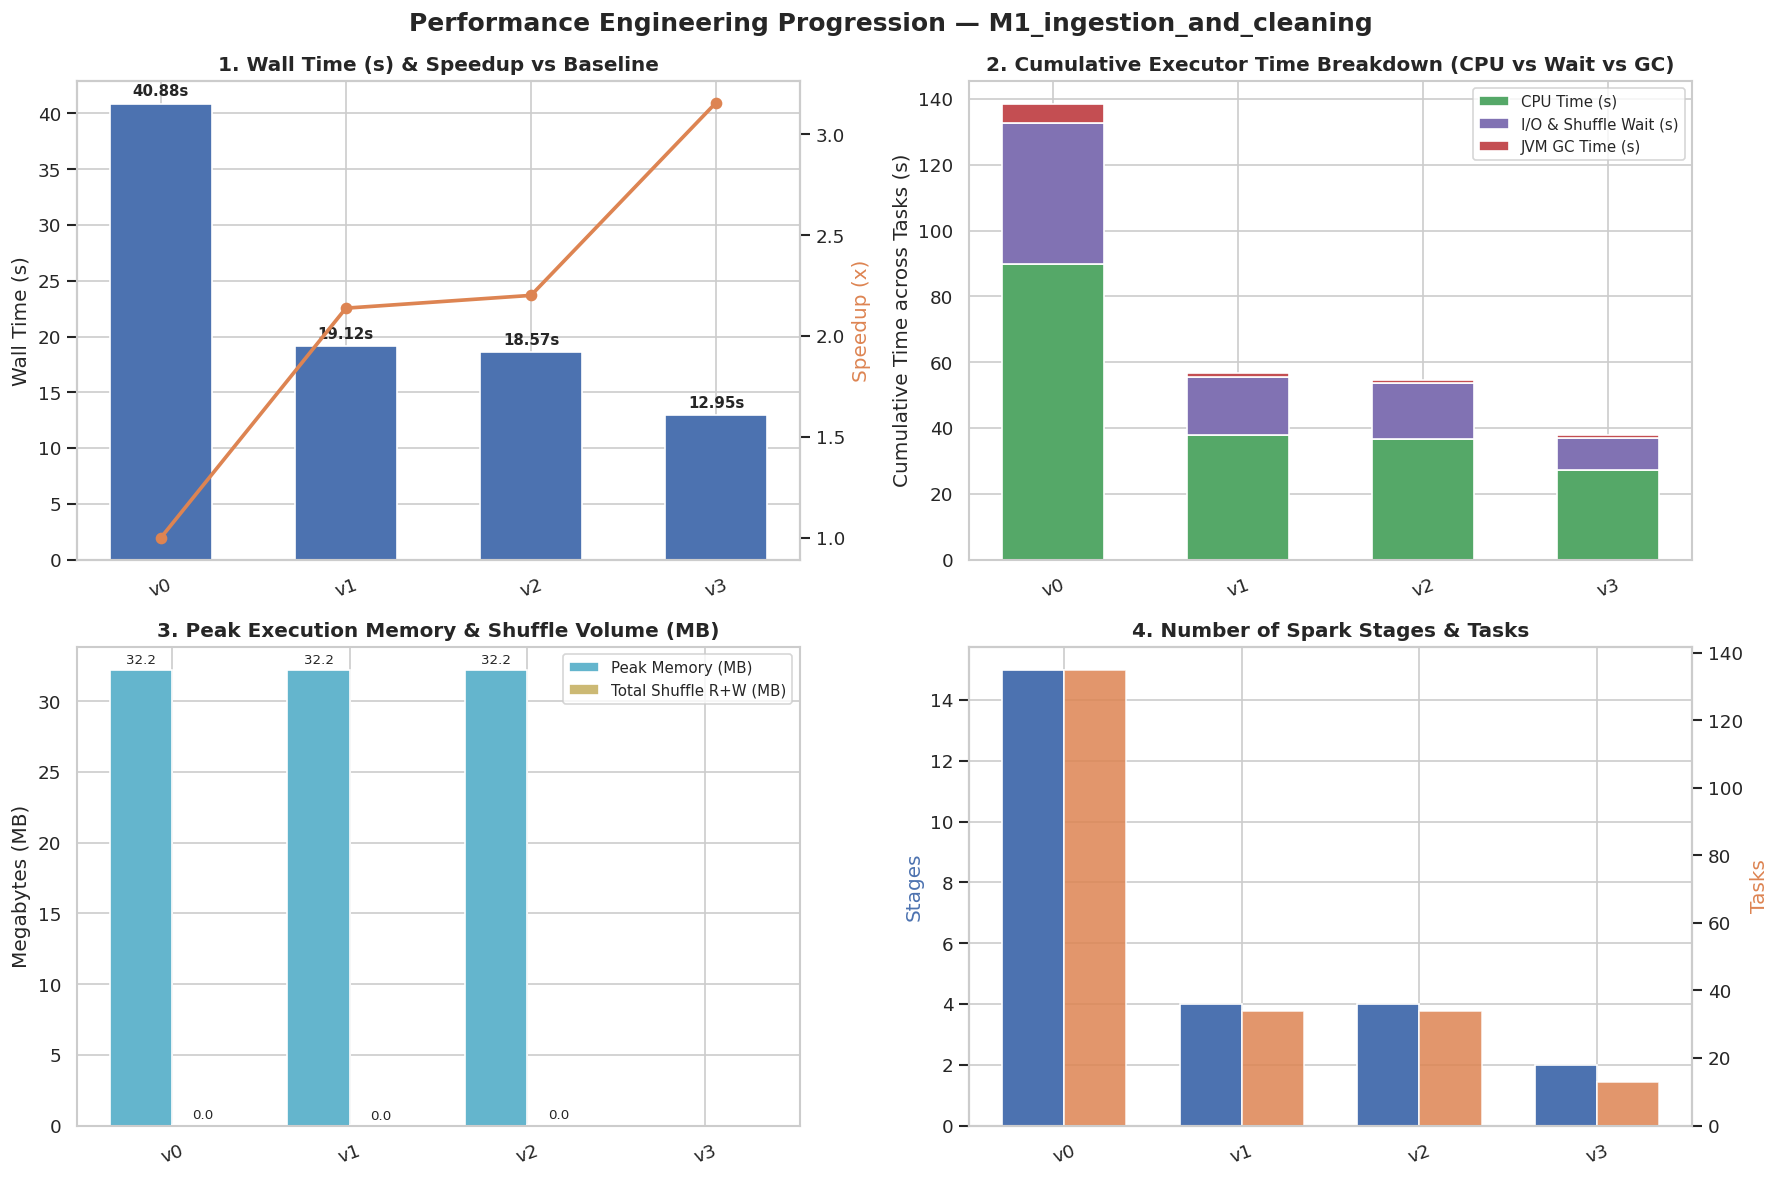

Chart saved to: /output/plots/benchmark_M1_ingestion_and_cleaning.png


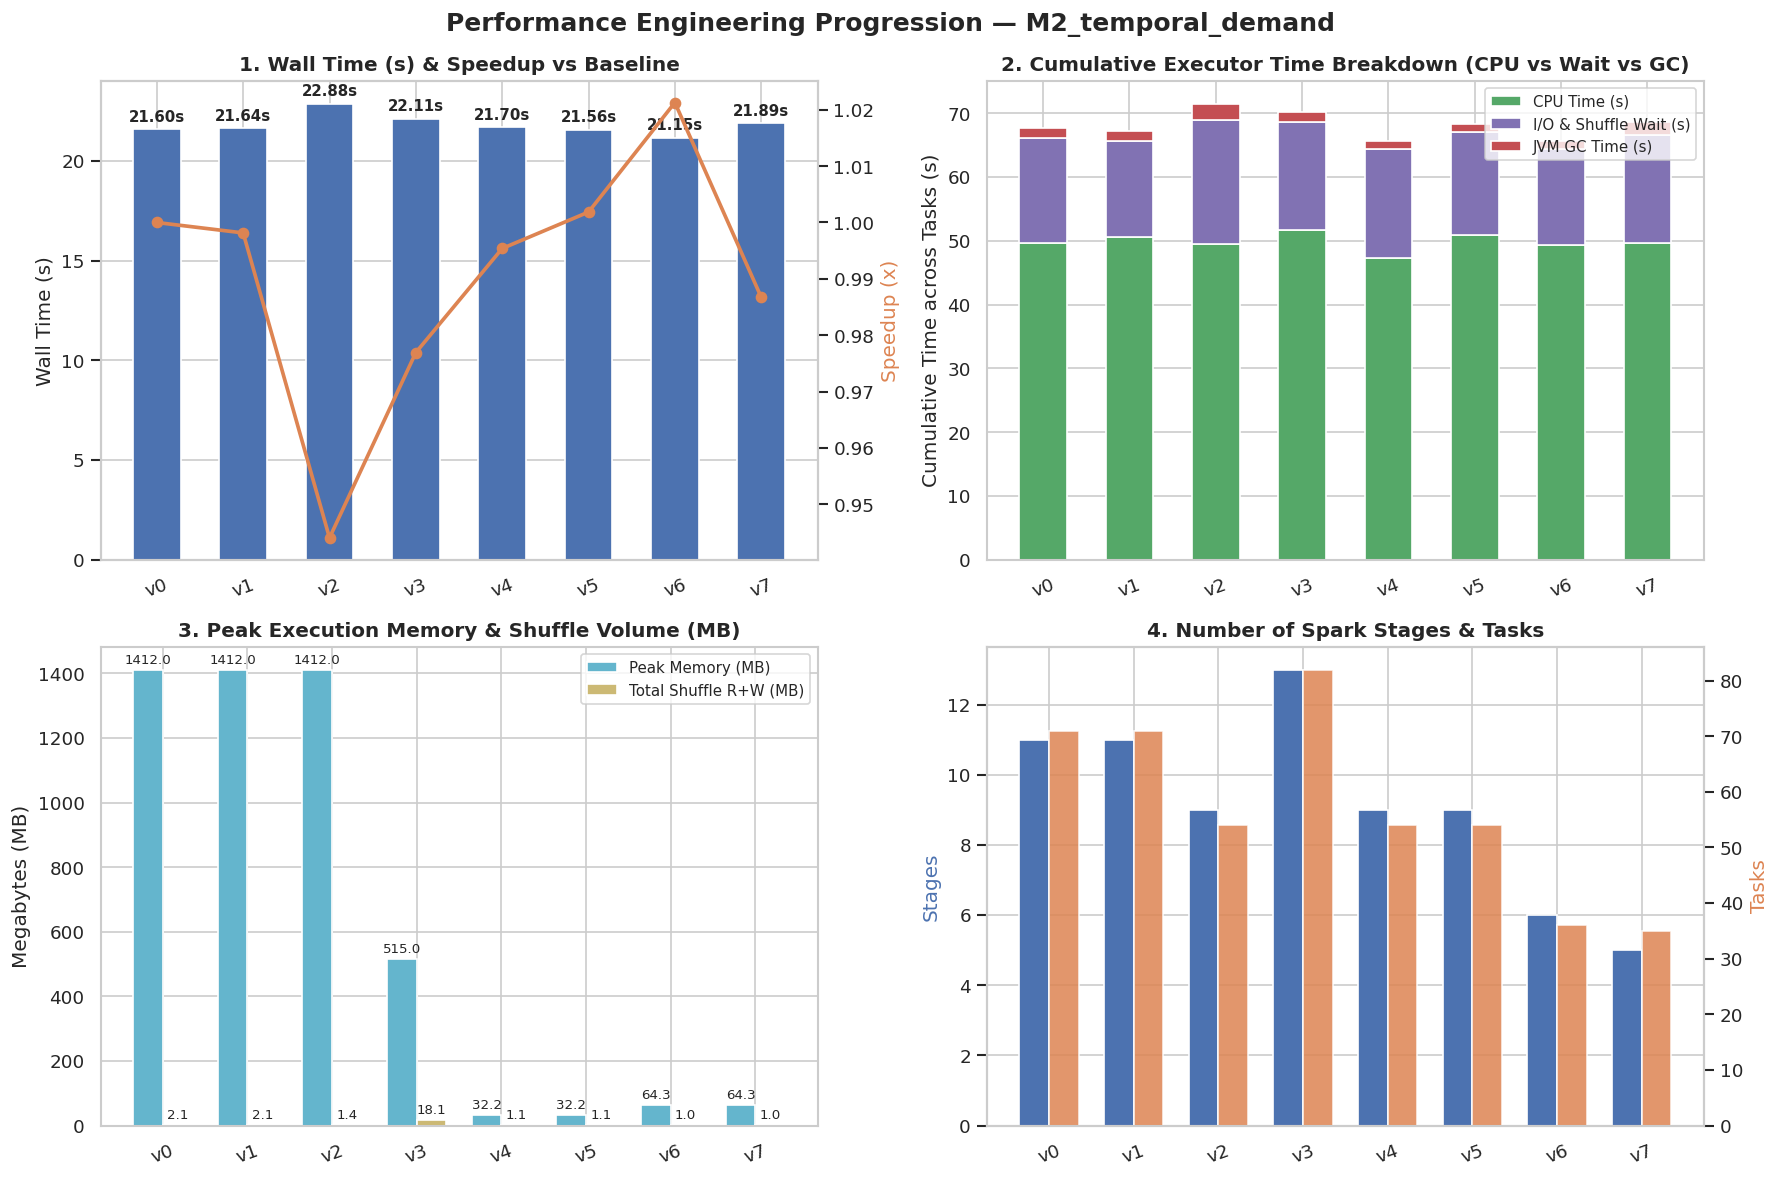

Chart saved to: /output/plots/benchmark_M2_temporal_demand.png


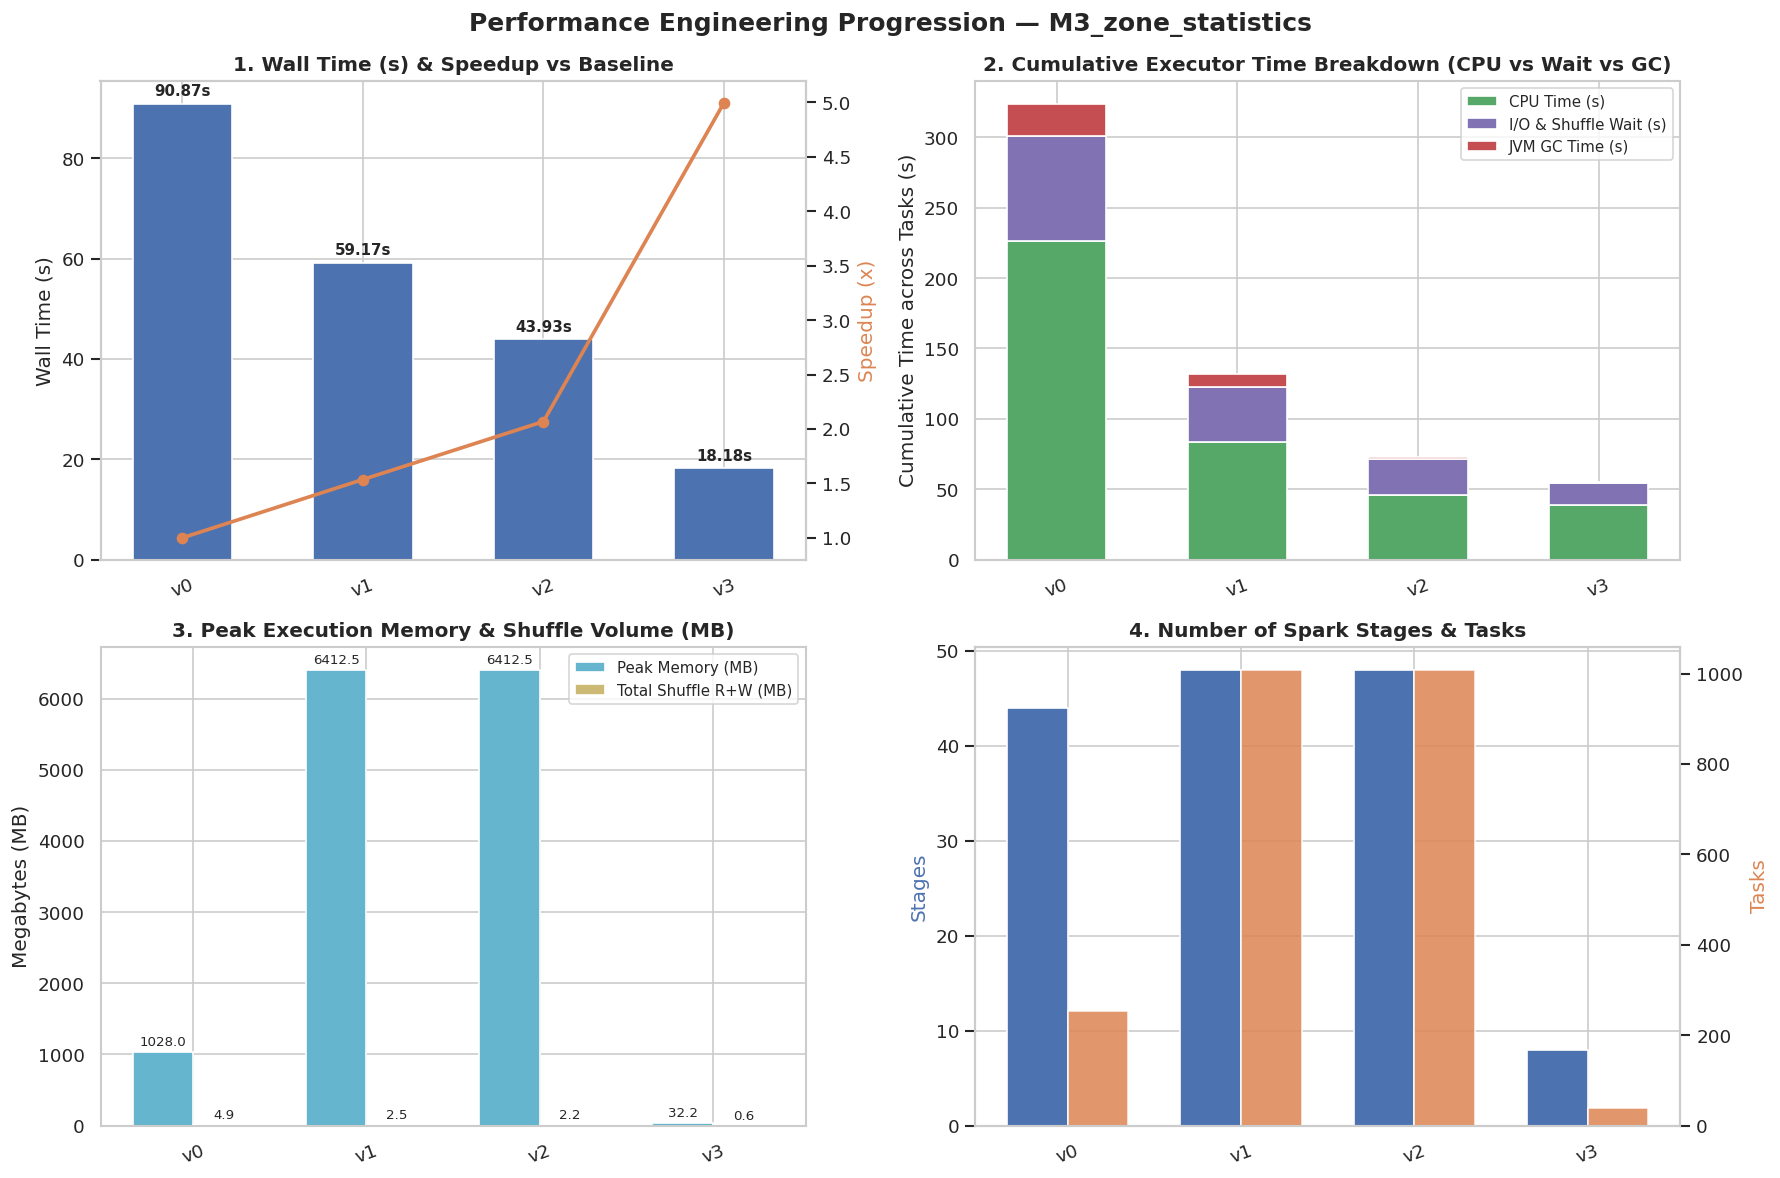

Chart saved to: /output/plots/benchmark_M3_zone_statistics.png


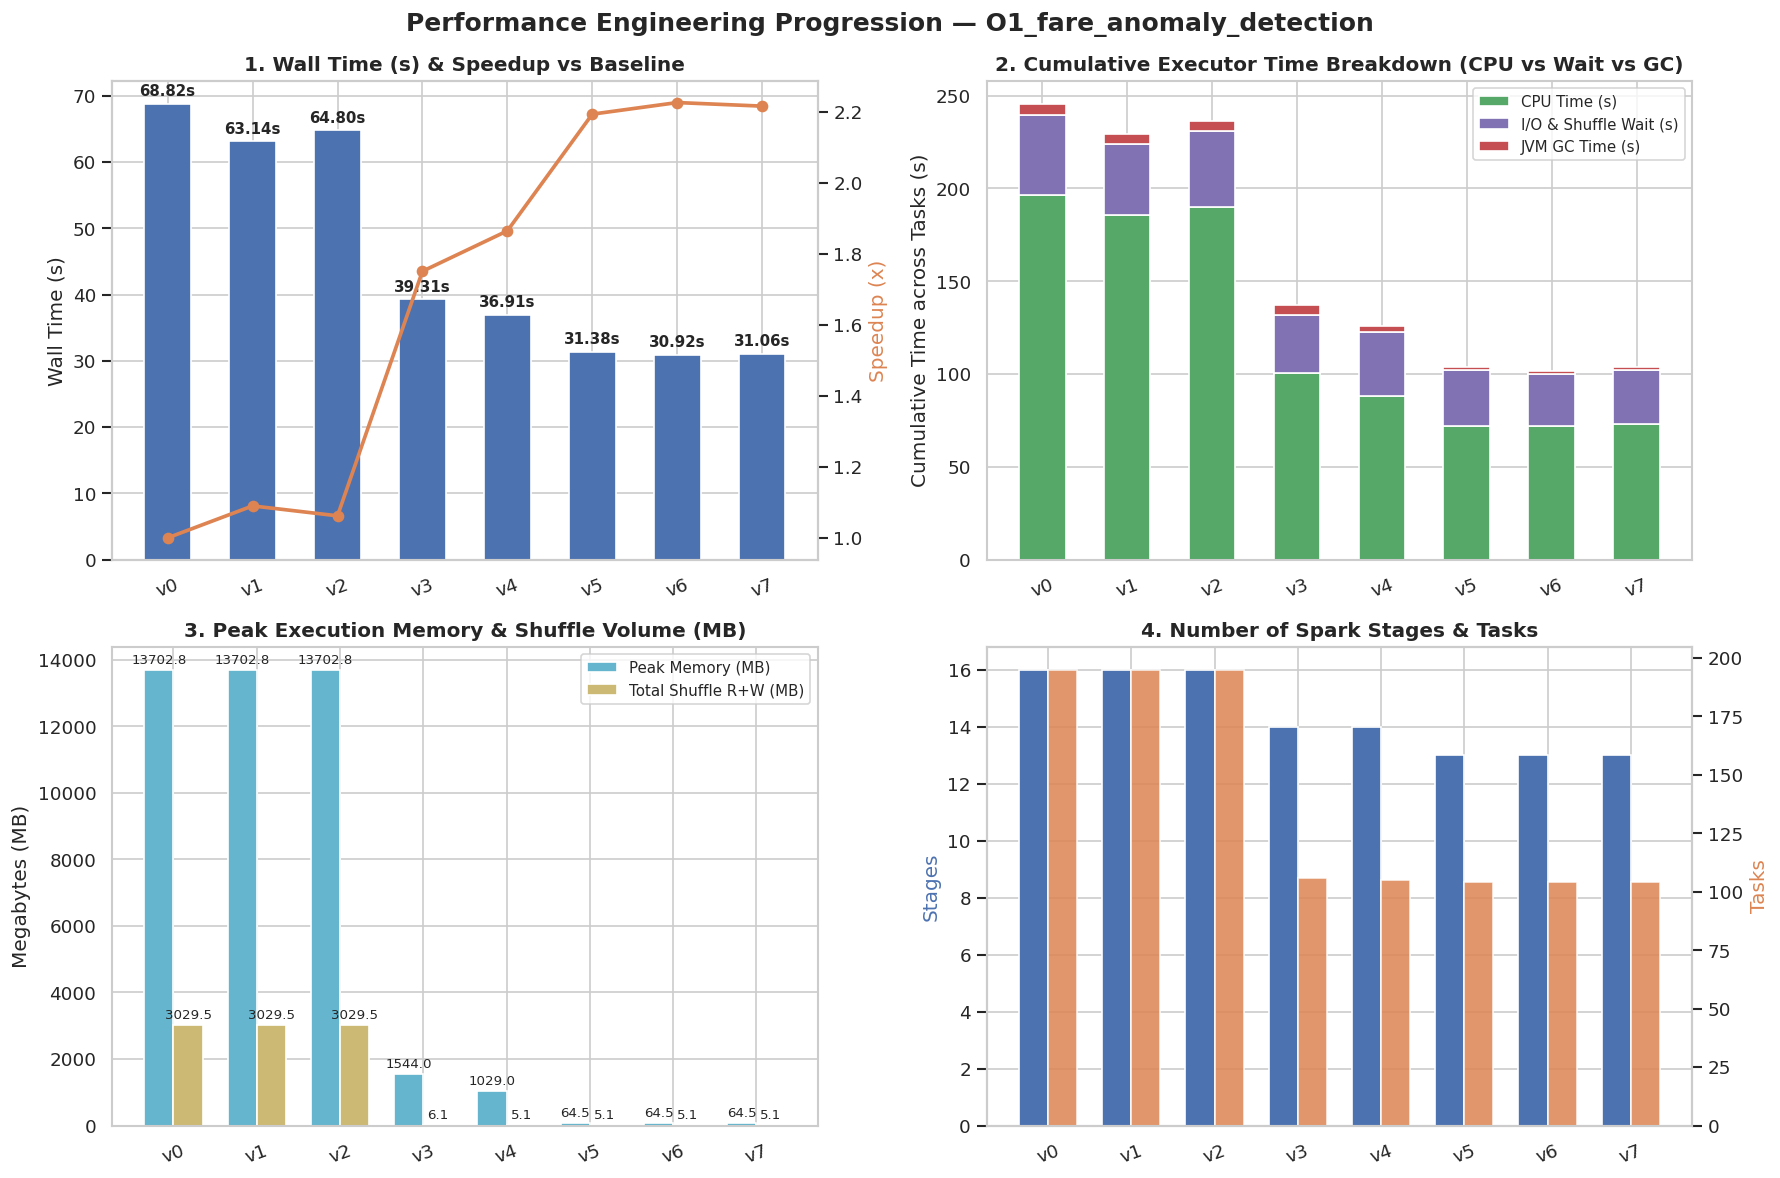

Chart saved to: /output/plots/benchmark_O1_fare_anomaly_detection.png


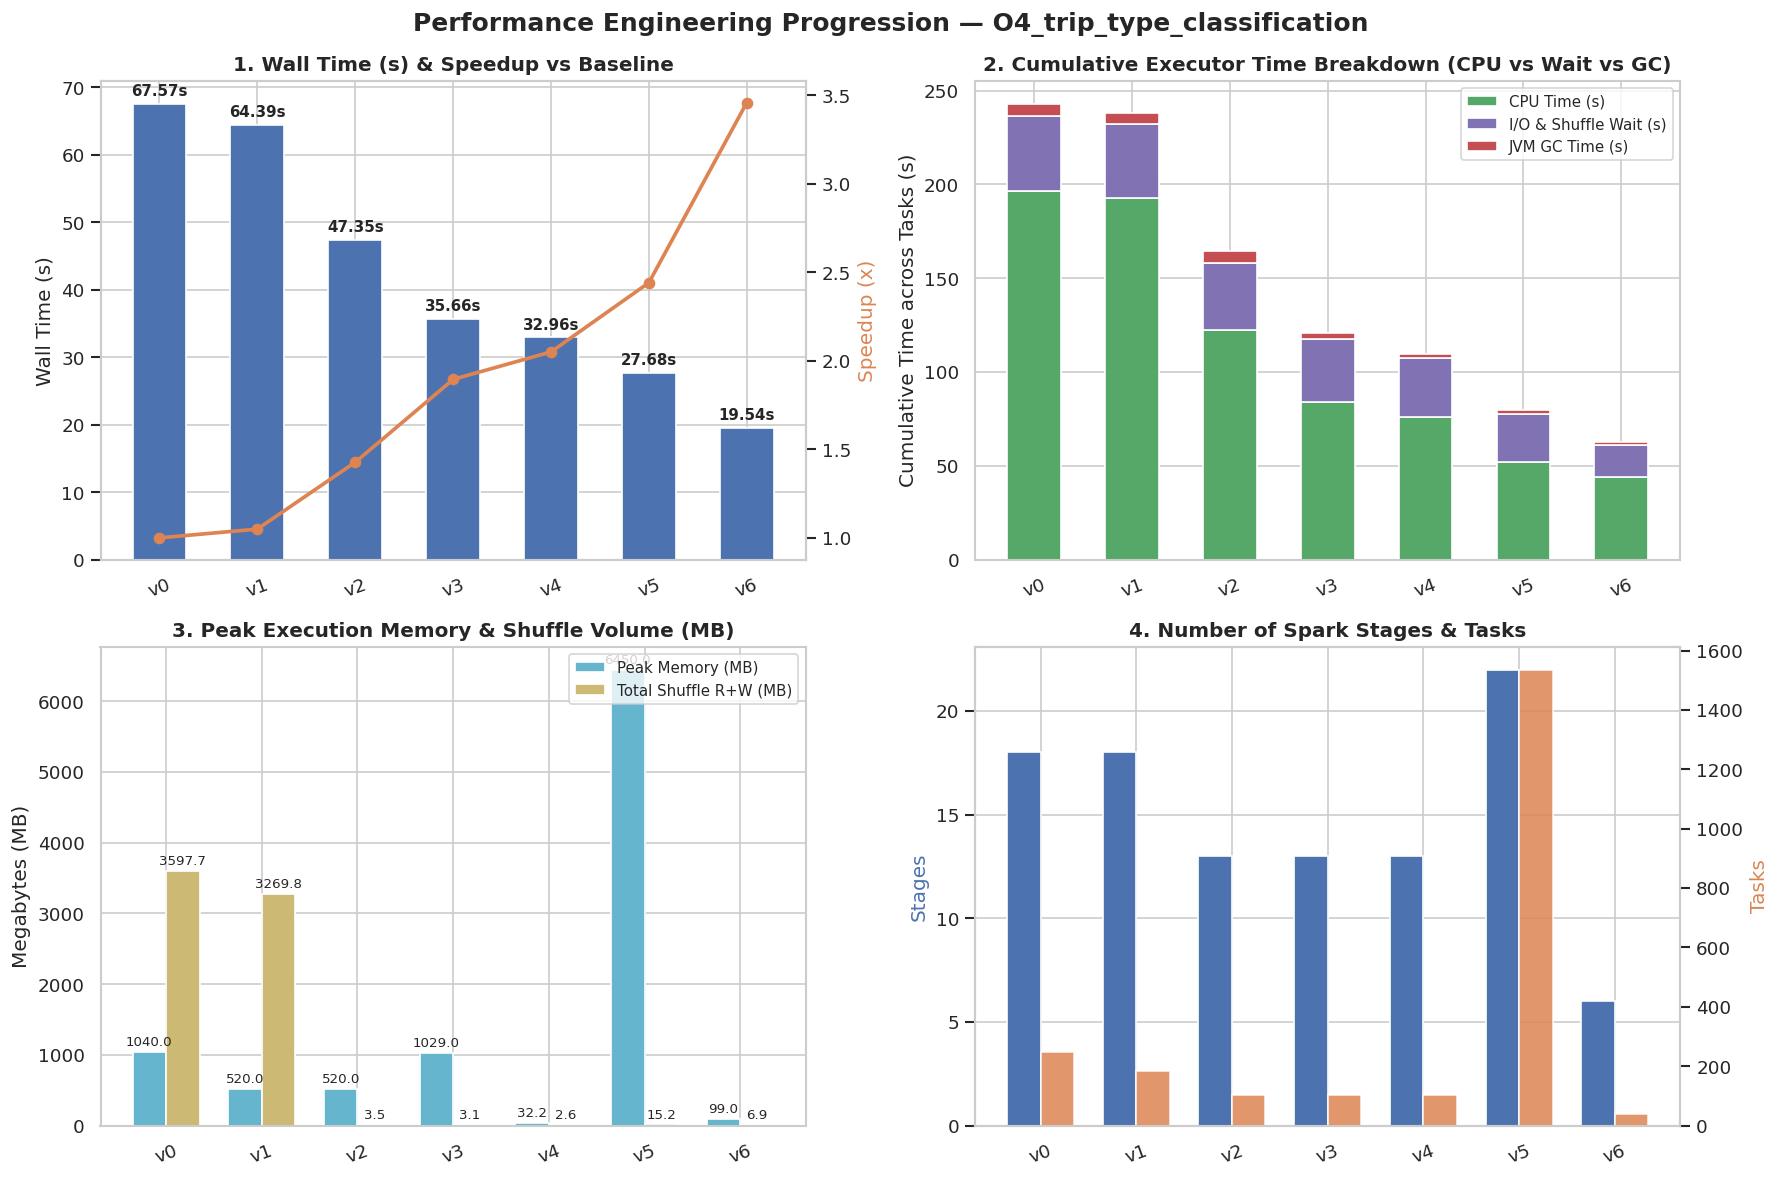

Chart saved to: /output/plots/benchmark_O4_trip_type_classification.png


In [3]:
def plot_operation_benchmarks(df_op, op_name):
    df_op = df_op.copy().reset_index(drop=True)
    base_wall = df_op.loc[0, "wall_time_s"] if df_op.loc[0, "wall_time_s"] > 0 else 1.0
    df_op["speedup"] = base_wall / df_op["wall_time_s"].replace(0, np.nan)

    versions = df_op["version"].tolist()
    x = np.arange(len(versions))

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f"Performance Engineering Progression — {op_name}", fontsize=15, fontweight="bold")

    # 1. Wall Time & Speedup
    ax1 = axes[0, 0]
    bars = ax1.bar(x, df_op["wall_time_s"], color="#4C72B0", width=0.55, label="Wall Time (s)")
    ax1.set_title("1. Wall Time (s) & Speedup vs Baseline", fontweight="bold")
    ax1.set_xticks(x)
    ax1.set_xticklabels(versions, rotation=20)
    ax1.set_ylabel("Wall Time (s)")
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.2f}s", (bar.get_x() + bar.get_width() / 2, h),
                     ha="center", va="bottom", fontsize=9, fontweight="bold", xytext=(0, 3), textcoords="offset points")

    if len(versions) > 1:
        ax1_twin = ax1.twinx()
        ax1_twin.plot(x, df_op["speedup"], color="#DD8452", marker="o", linewidth=2.2, label="Speedup (x)")
        ax1_twin.set_ylabel("Speedup (x)", color="#DD8452")
        ax1_twin.grid(False)

    # 2. Decomposition: CPU vs GC vs I/O & Wait
    ax2 = axes[0, 1]
    ax2.bar(x, df_op["exec_cpu_s"], width=0.55, label="CPU Time (s)", color="#55A868")
    ax2.bar(x, df_op["io_wait_s"], width=0.55, bottom=df_op["exec_cpu_s"], label="I/O & Shuffle Wait (s)", color="#8172B3")
    ax2.bar(x, df_op["jvm_gc_s"], width=0.55, bottom=df_op["exec_cpu_s"] + df_op["io_wait_s"], label="JVM GC Time (s)", color="#C44E52")
    ax2.set_title("2. Cumulative Executor Time Breakdown (CPU vs Wait vs GC)", fontweight="bold")
    ax2.set_xticks(x)
    ax2.set_xticklabels(versions, rotation=20)
    ax2.set_ylabel("Cumulative Time across Tasks (s)")
    ax2.legend(loc="upper right", fontsize=9)

    # 3. Peak Execution Memory & Shuffle Volume
    ax3 = axes[1, 0]
    w = 0.35
    b1 = ax3.bar(x - w/2, df_op["peak_mem_mb"], width=w, label="Peak Memory (MB)", color="#64B5CD")
    b2 = ax3.bar(x + w/2, df_op["total_shuffle_mb"], width=w, label="Total Shuffle R+W (MB)", color="#CCB974")
    ax3.set_title("3. Peak Execution Memory & Shuffle Volume (MB)", fontweight="bold")
    ax3.set_xticks(x)
    ax3.set_xticklabels(versions, rotation=20)
    ax3.set_ylabel("Megabytes (MB)")
    ax3.legend(loc="upper right", fontsize=9)
    for bar in list(b1) + list(b2):
        h = bar.get_height()
        if h > 0:
            ax3.annotate(f"{h:.1f}", (bar.get_x() + bar.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")

    # 4. Stages & Tasks
    ax4 = axes[1, 1]
    ax4.bar(x - w/2, df_op["num_stages"], width=w, label="Stages", color="#4C72B0")
    ax4_twin = ax4.twinx()
    ax4_twin.bar(x + w/2, df_op["num_tasks"], width=w, label="Tasks", color="#DD8452", alpha=0.85)
    ax4.set_title("4. Number of Spark Stages & Tasks", fontweight="bold")
    ax4.set_xticks(x)
    ax4.set_xticklabels(versions, rotation=20)
    ax4.set_ylabel("Stages", color="#4C72B0")
    ax4_twin.set_ylabel("Tasks", color="#DD8452")
    ax4_twin.grid(False)

    plt.tight_layout()
    out_file = os.path.join(PLOTS_DIR, f"benchmark_{op_name}.png")
    plt.savefig(out_file, bbox_inches="tight")
    plt.show()
    print(f"Chart saved to: {out_file}")

if not df_runs.empty:
    for op_name, group in df_runs.groupby("operation", sort=False):
        plot_operation_benchmarks(group, op_name)


### 5. Evolution of Wall Time and Peak Memory per Version

Two charts with one line per operation, in version order (v0, v1, ...):
1. **Wall time** of the operation (median of the runs; the shaded band is the min-max range when there are repeated runs).
2. **Peak execution memory** reported by Spark (log scale, because it goes from a few MB to several GB).

Both are saved as PNG and PDF in `output/plots/` (`evolution_time.*`, `evolution_memory.*`) so they can go straight into the report.


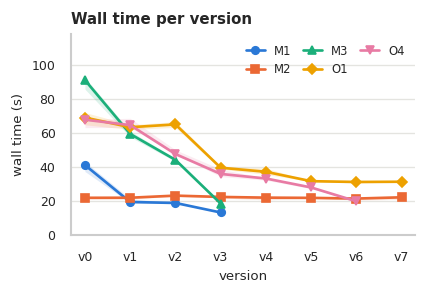

Chart saved to: /output/plots/evolution_time.png/.pdf


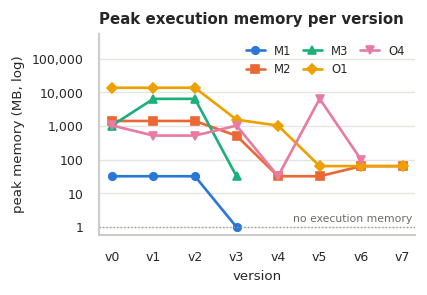

Chart saved to: /output/plots/evolution_memory.png/.pdf


In [4]:
# Fixed colour and marker per operation, so the same operation looks the same in both charts
OP_STYLE = {
    "M1": ("#2a78d6", "o"), "M2": ("#eb6834", "s"), "M3": ("#1baf7a", "^"),
    "O1": ("#eda100", "D"), "O4": ("#e87ba4", "v"),
}
SHORT = lambda op: op.split("_")[0]

EVO_RC = {"font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5}

def _evolution_axes(title, ylabel):
    fig, ax = plt.subplots(figsize=(3.6, 2.5))
    ax.set_title(title, fontsize=9, fontweight="bold", loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("version")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#e4e4e0", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    return fig, ax

def _finish(fig, ax, df, name):
    max_v = int(df["version"].str.extract(r"(\d+)")[0].astype(int).max())
    ax.set_xticks(range(max_v + 1))
    ax.set_xticklabels([f"v{i}" for i in range(max_v + 1)])
    ax.set_xlim(-0.3, max_v + 0.3)
    ax.legend(loc="upper right", fontsize=7, frameon=False, ncol=3, handlelength=1.6, columnspacing=1.0)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(PLOTS_DIR, f"{name}.{ext}"), bbox_inches="tight")
    plt.show()
    print(f"Chart saved to: {os.path.join(PLOTS_DIR, name)}.png/.pdf")

def plot_time_evolution(df):
    fig, ax = _evolution_axes("Wall time per version", "wall time (s)")
    for op in dict.fromkeys(df["operation"]):
        d = df[df["operation"] == op]
        x = d["version"].str.extract(r"(\d+)")[0].astype(int).to_numpy()
        color, marker = OP_STYLE.get(SHORT(op), ("#555555", "o"))
        if (d["runs"] > 1).any():
            ax.fill_between(x, d["wall_min_s"], d["wall_max_s"], color=color, alpha=0.15, linewidth=0)
        ax.plot(x, d["wall_time_s"], color=color, marker=marker, markersize=4.5, linewidth=1.6, label=SHORT(op))
    ax.set_ylim(0, df["wall_time_s"].max() * 1.3)  # headroom for the legend
    _finish(fig, ax, df, "evolution_time")

def plot_memory_evolution(df):
    fig, ax = _evolution_axes("Peak execution memory per version", "peak memory (MB, log)")
    floor = 1.0  # versions that use no Spark execution memory are drawn on this line
    for op in dict.fromkeys(df["operation"]):
        d = df[df["operation"] == op]
        x = d["version"].str.extract(r"(\d+)")[0].astype(int).to_numpy()
        y = d["peak_mem_mb"].clip(lower=floor).to_numpy()
        color, marker = OP_STYLE.get(SHORT(op), ("#555555", "o"))
        ax.plot(x, y, color=color, marker=marker, markersize=4.5, linewidth=1.6, label=SHORT(op))
    ax.set_yscale("log")
    ax.set_ylim(floor * 0.6, df["peak_mem_mb"].max() * 40)  # headroom for the legend
    ax.axhline(floor, color="#9a9a94", linewidth=0.8, linestyle=":")
    ax.text(0.99, floor * 1.25, "no execution memory", transform=ax.get_yaxis_transform(), ha="right",
            va="bottom", fontsize=6.5, color="#6b6b66")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    _finish(fig, ax, df, "evolution_memory")

if not df_runs.empty:
    with plt.rc_context(EVO_RC):
        plot_time_evolution(df_runs)
        plot_memory_evolution(df_runs)


### 4. Stage Breakdown & Task Skew Diagnosis


In [5]:
if not df_stages.empty:
    stage_display = df_stages.copy()
    stage_display["skew_ratio_display"] = stage_display.apply(
        lambda r: f"{r['skew_ratio']:.1f}x (!)" if r["skew_warning"] else f"{r['skew_ratio']:.1f}x", axis=1
    )
    cols = ["version", "operation", "stage_id", "stage_name", "num_tasks",
            "run_time_ms", "cpu_time_ms", "gc_time_ms", "peak_mem_mb",
            "shuffle_read_kb", "shuffle_write_kb", "med_task_ms", "max_task_ms", "skew_ratio_display"]
    display(stage_display[cols].round(2))


,version,operation,stage_id,stage_name,num_tasks,run_time_ms,cpu_time_ms,gc_time_ms,peak_mem_mb,shuffle_read_kb,shuffle_write_kb,med_task_ms,max_task_ms,skew_ratio_display
0,v0,M1_ingestion_and_cleaning,0,M1_ingestion_and_cleaning,1,285,70,7,0.0,0.00,0.00,285,285,1.0x
1,v0,M1_ingestion_and_cleaning,1,M1_ingestion_and_cleaning,16,3947,1766,126,0.0,0.00,0.91,81,963,11.9x (!)
2,v0,M1_ingestion_and_cleaning,2,$anonfun$withThreadLocalCaptured$1 at Complet,16,0,0,0,0.0,0.00,0.00,0,0,1.0x
3,v0,M1_ingestion_and_cleaning,3,M1_ingestion_and_cleaning,1,101,67,7,0.0,0.91,0.00,101,101,1.0x
4,v0,M1_ingestion_and_cleaning,4,M1_ingestion_and_cleaning,16,63014,42831,2326,4.0,0.00,1.09,4232,7897,1.9x
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,v6,O4_trip_type_classification,3,O4_trip_type_classification,1,887,791,0,0.0,0.00,0.00,887,887,1.0x
460,v6,O4_trip_type_classification,4,O4_trip_type_classification,16,60306,42185,1556,4.0,0.00,3549.05,4469,6076,1.4x
461,v6,O4_trip_type_classification,5,$anonfun$withThreadLocalCaptured$1 at Complet,16,0,0,0,0.0,0.00,0.00,0,0,1.0x
462,v6,O4_trip_type_classification,6,O4_trip_type_classification,3,749,448,0,99.0,3549.05,0.00,247,302,1.2x
